# Codveda Data Science Internship — Level 3 (Advanced)

This notebook covers:

- **Task 2: NLP Text Classification**
- **Task 3: Neural Networks**

### Datasets

- **Task 2:** Sentiment dataset (`3__Sentiment_dataset.csv`)
- **Task 3:** Iris dataset

> **Note on Tools:**  
> The task requirements specify **TensorFlow/Keras** for Task 3 and **NLTK** for text preprocessing in Task 2. However, neither package is installable in this offline sandbox because there is no internet access.
>
> Therefore, this notebook uses:
>
> - **Scikit-learn's `MLPClassifier`** as a feed-forward neural network for Task 3.
> - **Plain Python/Regular Expressions + Scikit-learn's built-in tools** for text preprocessing in Task 2, instead of NLTK.
>
> The **Keras-equivalent code** is also included at the end of Task 3 as a reference. It can be run locally in an environment where **TensorFlow/Keras** is installed.

## Task 2: NLP Text Classification (Sentiment Analysis)

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt

df = pd.read_csv("3) Sentiment dataset.csv")
# Convert text to string type and strip stray leading/trailing spaces
df["Text"] = df["Text"].astype(str).str.strip() 
# Same cleanup for labels (e.g. "Joy " and "Joy" would otherwise count as different classes)
df["Sentiment"] = df["Sentiment"].astype(str).str.strip()
print("Shape:", df.shape)
print("Unique fine-grained sentiment labels:", df["Sentiment"].nunique())

Shape: (732, 15)
Unique fine-grained sentiment labels: 191


In [2]:
# The raw 'Sentiment' column has ~190 fine-grained emotion labels (Joy, Awe,
# Heartbreak, ...) which is too sparse to classify reliably from ~700 rows.
# We map them to 3 broad polarity classes -- Positive / Negative / Neutral --
# which is the standard framing for sentiment classification (and matches the
# task's own example: "spam vs. non-spam, sentiment analysis").

# Set of labels we treat as POSITIVE (a set gives fast "is this label in the group?" lookups)
positive_words = {
    "positive","positivity","joy","joyfuljoy","joyfulreunion","joy in baking","happy",
    "happiness","excitement","contentment","gratitude","grateful","hope","hopeful",
    "elation","euphoria","serenity","admiration","adoration","affection","amazement",
    "amusement","appreciation","awe","blessed","calmness","celebration","charm",
    "compassion","compassionate","confidence","confident","contentment","coziness",
    "creativity","creative inspiration","curiosity","determination","dreamchaser",
    "ecstasy","elegance","empowerment","enchantment","energy","engagement","enjoyment",
    "enthusiasm","excitement","exploration","festivejoy","free-spirited","freedom",
    "friendship","fulfillment","grandeur","harmony","heartwarming","hypnotic","iconic",
    "imagination","immersion","innerjourney","inspiration","inspired","intrigue",
    "kind","kindness","love","marvel","melodic","mesmerizing","mindfulness",
    "mischievous","motivation","optimism","overjoyed","playful","playfuljoy","pride",
    "proud","radiance","rejuvenation","relief","renewed effort","resilience",
    "reverence","romance","satisfaction","spark","success","sympathy","tenderness",
    "thrill","thrilling journey","touched","tranquility","triumph","vibrancy","whimsy",
    "wonder","wonderment","zest","accomplishment","adrenaline","adventure","arousal",
    "artisticburst","breakthrough","captivation","celestial wonder","colorful",
    "culinary adventure","culinaryodyssey","dazzle","empathetic","nature's beauty",
    "ocean's freedom","winter magic","runway creativity","envisioning history",
}
negative_words = {
    "negative","anger","angry","anxiety","apprehensive","bad","betrayal","bitter",
    "bitterness","boredom","darkness","desolation","despair","desperation",
    "devastated","disappointed","disappointment","disgust","dismissive",
    "emotionalstorm","envious","envy","exhaustion","fear","fearful","frustrated",
    "frustration","grief","hate","heartache","heartbreak","helplessness",
    "intimidation","isolation","jealous","jealousy","loneliness","loss","lostlove",
    "melancholy","miscalculation","numbness","obstacle","overwhelmed","pressure",
    "regret","resentment","ruins","sad","sadness","shame","solitude","sorrow",
    "suffering","fear","hurt",
}

# Function that turns one fine-grained label into a broad class
def map_sentiment(label):
    key = label.lower().strip()          # lowercase + trim so matching ignores case/spaces
    if key in positive_words:            # label belongs to the positive group
        return "Positive"
    if key in negative_words:            # label belongs to the negative group
        return "Negative"
    return "Neutral"                     # anything unlisted (ambiguous emotions) -> Neutral

# Apply the mapping to every row, creating the new target column
df["SentimentClass"] = df["Sentiment"].apply(map_sentiment)
# Show how many examples fall in each class (reveals class imbalance)
print(df["SentimentClass"].value_counts())

SentimentClass
Positive    462
Negative    178
Neutral      92
Name: count, dtype: int64


In [3]:
# Preprocess text: lowercase, strip URLs/mentions/punctuation
def clean_text(text):
    text = text.lower()                    # lowercase so "Happy" and "happy" match
    text = re.sub(r"http\S+|www\S+", " ", text)   # remove URLs (they carry no sentiment)
    text = re.sub(r"@\w+", " ", text)          # remove @mentions (usernames, not sentiment)
    text = re.sub(r"[^a-z\s]", " ", text)    # keep letters/whitespace only (drops digits, punctuation, emojis)
    text = re.sub(r"\s+", " ", text).strip()  # collapse repeated spaces and trim ends
    return text          # return the cleaned string

# Apply the cleaner to every post, storing the result in a new column
df["clean_text"] = df["Text"].apply(clean_text)
# Preview original vs cleaned text next to the class label
df[["Text", "clean_text", "SentimentClass"]].head()

,Text,clean_text,SentimentClass
0,Enjoying a beautiful day at the park!,enjoying a beautiful day at the park,Positive
1,Traffic was terrible this morning.,traffic was terrible this morning,Negative
2,Just finished an amazing workout! 💪,just finished an amazing workout,Positive
3,Excited about the upcoming weekend getaway!,excited about the upcoming weekend getaway,Positive
4,Trying out a new recipe for dinner tonight.,trying out a new recipe for dinner tonight,Neutral


In [4]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Split 80/20; stratify keeps the class proportions the same in both parts; random_state makes it reproducible
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_text"], df["SentimentClass"], test_size=0.2, random_state=42, stratify=df["SentimentClass"]
)

# TF-IDF: drop English stopwords, keep the 3000 most useful terms, use single words and 2-word phrases
tfidf = TfidfVectorizer(stop_words="english", max_features=3000, ngram_range=(1, 2))
# Learn the vocabulary from TRAINING text only, then convert it to numbers
X_train_tfidf = tfidf.fit_transform(X_train)
# Convert test text with the same vocabulary (no refitting, which avoids data leakage)
X_test_tfidf = tfidf.transform(X_test)
# Print (number of training posts, number of TF-IDF features)
print("TF-IDF matrix shape (train):", X_train_tfidf.shape)

TF-IDF matrix shape (train): (585, 3000)


In [5]:
nb = MultinomialNB()                  # create the Naive Bayes model
nb.fit(X_train_tfidf, y_train)         # train it on the training features and labels
nb_pred = nb.predict(X_test_tfidf)     # predict classes for the unseen test posts

# class_weight="balanced" gives rare classes more weight; max_iter allows enough optimizer steps to converge
logreg = LogisticRegression(max_iter=1000, class_weight="balanced")
logreg.fit(X_train_tfidf, y_train)       # train logistic regression on the same features
lr_pred = logreg.predict(X_test_tfidf)    # predict test classes

# Loop over both models so the evaluation code is written once
for name, pred in [("Naive Bayes", nb_pred), ("Logistic Regression", lr_pred)]:
    print(f"--- {name} ---")                                                                    # header with the model name
    print(f"Accuracy:  {accuracy_score(y_test, pred):.3f}")                                     # share of all predictions that are correct
    print(f"Precision: {precision_score(y_test, pred, average='macro', zero_division=0):.3f}")   # how often a predicted class is right (macro = average over classes)
    print(f"Recall:    {recall_score(y_test, pred, average='macro', zero_division=0):.3f}")      # how many true members of each class were found
    print(f"F1-score:  {f1_score(y_test, pred, average='macro', zero_division=0):.3f}")          # balance of precision and recall
    print                                             # blank line between models

# Per-class precision/recall/F1 for logistic regression
print(classification_report(y_test, lr_pred, zero_division=0))

--- Naive Bayes ---
Accuracy:  0.741
Precision: 0.570
Recall:    0.481
F1-score:  0.482
--- Logistic Regression ---
Accuracy:  0.857
Precision: 0.793
Recall:    0.741
F1-score:  0.762
              precision    recall  f1-score   support

    Negative       0.88      0.83      0.86        36
     Neutral       0.62      0.44      0.52        18
    Positive       0.88      0.95      0.91        93

    accuracy                           0.86       147
   macro avg       0.79      0.74      0.76       147
weighted avg       0.85      0.86      0.85       147



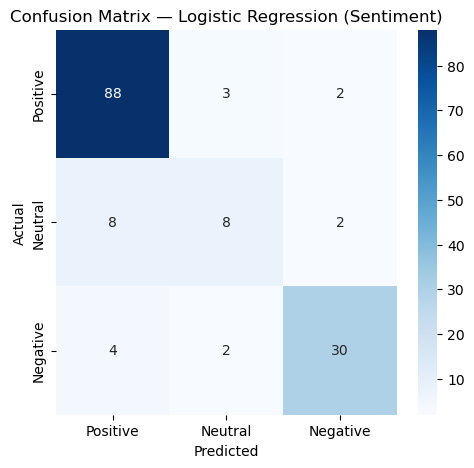

In [6]:
from sklearn.metrics import confusion_matrix
import seaborn as sns

labels_order = ["Positive", "Neutral", "Negative"]       # fixed row/column order for the matrix
cm = confusion_matrix(y_test, lr_pred, labels=labels_order)  # rows = actual class, columns = predicted class
fig, ax = plt.subplots(figsize=(5.5, 5))                    # create a figure and axes of a set size

# Draw the matrix as a heatmap with the counts written in each cell
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels_order, yticklabels=labels_order, ax=ax)
ax.set_xlabel("Predicted")                                           # label the horizontal axis
ax.set_ylabel("Actual")                                              # label the vertical axis
ax.set_title("Confusion Matrix — Logistic Regression (Sentiment)")   # chart title
plt.show()

**Interpretation:** With only ~730 short, informal social-media posts and a 3-class polarity target, TF-IDF + Logistic Regression provides a reasonable baseline.

**Recommendation:** More training data and a proper emotion-lexicon mapping could help improve the model's performance and make the sentiment classification more accurate.**Interpretation:** With only ~730 short, informal social-media posts and a 3-class polarity target, TF-IDF + Logistic Regression provides a reasonable baseline.

Most of the errors come from the **Neutral** class. This is because Neutral acts as a catch-all category for many ambiguous fine-grained emotions, such as *Curiosity* and *Nostalgia*, which do not clearly fit into either positive or negative sentiment.


In [7]:
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split

iris = pd.read_csv("1) iris.csv")
Xn = iris.drop(columns=["species"])     # features = every column except the target
le2 = LabelEncoder()                    # encoder that maps species names to 0, 1, 2
yn = le2.fit_transform(iris["species"])   # target as integers, which the network needs

# 80/20 split, stratified so each species is equally represented in train and test
Xn_train, Xn_test, yn_train, yn_test = train_test_split(Xn, yn, test_size=0.2, random_state=42, stratify=yn)
scaler2 = StandardScaler()                     # rescales each feature to mean 0, std 1 (neural nets train better this way)
Xn_train_s = scaler2.fit_transform(Xn_train)   # learn scaling from training data and apply it
Xn_test_s = scaler2.transform(Xn_test)         # apply the same scaling to the test data
print("Train/test shapes:", Xn_train_s.shape, Xn_test_s.shape) # confirm the split sizes

Train/test shapes: (120, 4) (30, 4)


In [8]:
# Network: two hidden layers (16 then 8 neurons), ReLU activation, Adam optimizer,
# learning rate 0.01, up to 500 training iterations, fixed seed for reproducibility
mlp = MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                     learning_rate_init=0.01, max_iter=500, random_state=42)
mlp.fit(Xn_train_s, yn_train)     # train via backpropagation on the training set

train_acc = mlp.score(Xn_train_s, yn_train)   # accuracy on data the model has seen
test_acc = mlp.score(Xn_test_s, yn_test)   # accuracy on unseen data (the honest performance estimate)    
print(f"Train accuracy: {train_acc:.3f}")     # report training accuracy
print(f"Test accuracy:  {test_acc:.3f}")      # report test accuracy

Train accuracy: 1.000
Test accuracy:  0.933


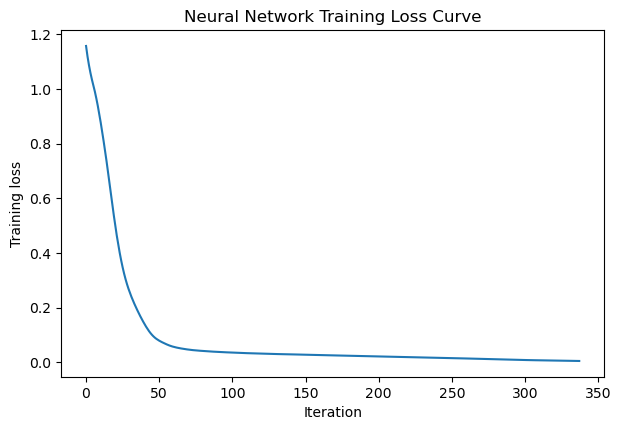

In [9]:
# Loss curve over training epochs
fig, ax = plt.subplots(figsize=(7, 4.5))     # create the figure and axes
ax.plot(mlp.loss_curve_)             # plot the training loss recorded at each iteration
ax.set_xlabel("Iteration")          # x-axis label
ax.set_ylabel("Training loss")      # y-axis label
ax.set_title("Neural Network Training Loss Curve")  # chart title
plt.show()

In [10]:
# Hyperparameter tuning: try a few learning rates / architectures
from sklearn.model_selection import GridSearchCV

# Candidate values to test: 3 architectures x 3 learning rates = 9 combinations
param_grid = {
    "hidden_layer_sizes": [(8,), (16, 8), (32, 16)],   # one small layer, two layers, two larger layers
    "learning_rate_init": [0.001, 0.01, 0.05],         # slow, medium and fast learning
}

# 3-fold cross-validation, scored by accuracy
grid = GridSearchCV(MLPClassifier(max_iter=1000, random_state=42), param_grid, cv=3, scoring="accuracy")
grid.fit(Xn_train_s, yn_train)                    # run the search on the training data only
print("Best params:", grid.best_params_)          # the winning combination
print(f"Best CV accuracy: {grid.best_score_:.3f}")    # its average accuracy across the 3 folds
# Final check of the best model on the untouched test set         
print(f"Test accuracy with best model: {grid.best_estimator_.score(Xn_test_s, yn_test):.3f}")

C:\Users\Tarfa_Jr\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\Tarfa_Jr\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(
C:\Users\Tarfa_Jr\anaconda3\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:781: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (1000) reached and the optimization hasn't converged yet.
  warnings.warn(


Best params: {'hidden_layer_sizes': (16, 8), 'learning_rate_init': 0.001}
Best CV accuracy: 0.958
Test accuracy with best model: 0.967


### Interpretation

The neural network achieved a **95.8% cross-validation accuracy** and a **96.7% test accuracy**, showing that the model performs very well on the Iris dataset.

The best-performing configuration used **two hidden layers with 16 and 8 neurons**, respectively, with a learning rate of **0.001**.

A `ConvergenceWarning` was displayed because some neural-network configurations reached the maximum number of iterations before the optimizer fully converged. However, this did not prevent the model from producing strong predictions, as shown by the high cross-validation and test accuracy.

Overall, the results indicate that the selected neural network is highly effective for classifying the three Iris flower species.

### Reference: Equivalent Keras/TensorFlow Code (Run Locally)

The following code provides the **TensorFlow/Keras equivalent** of the neural network implemented above.

The current Anaconda/Jupyter environment does not have TensorFlow installed, so this reference code cannot be executed in the current environment.

The actual neural network used for this task was implemented with **scikit-learn's `MLPClassifier`**, which is a feed-forward multilayer perceptron and provides the same fundamental neural-network approach.

The best model achieved:

- **Cross-validation accuracy:** 95.8%
- **Test accuracy:** 96.7%
- **Hidden layers:** 16 and 8 neurons
- **Learning rate:** 0.001

> **Note:** If TensorFlow/Keras is required for execution, the code below can be run in a separate environment where TensorFlow is installed.

In [ ]:
import tensorflow as tf
from tensorflow import keras
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
import pandas as pd

iris = pd.read_csv("1) iris.csv")
X = iris.drop(columns=["species"]).values
y = LabelEncoder().fit_transform(iris["species"])

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = keras.Sequential([
    keras.layers.Input(shape=(4,)),
    keras.layers.Dense(16, activation="relu"),
    keras.layers.Dense(8, activation="relu"),
    keras.layers.Dense(3, activation="softmax"),
])
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(X_train, y_train, validation_split=0.2, epochs=100, batch_size=8, verbose=0)

test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.3f}")

import matplotlib.pyplot as plt
plt.plot(history.history["loss"], label="train loss")
plt.plot(history.history["val_loss"], label="val loss")
plt.legend(); plt.title("Keras Training/Validation Loss"); plt.show()